# Wave energy farm: live demo
**Live** = computed now on 2,000 of the 10,218 layouts · **Full data** = from our results file.

In [1]:
#@title Setup: loads data, finds near-twin families, builds features, trains the model (click to expand)
import time, os, glob, io, zipfile, warnings
T0 = time.time()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore', category=FutureWarning)

BLUE, INK, INK2, MUTED, GRID, AXIS = '#2a78d6', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': AXIS, 'axes.labelcolor': INK2,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titlecolor': INK,
    'axes.facecolor': '#fcfcfb', 'figure.facecolor': '#fcfcfb'})
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#2a78d6', '#1c5cab', '#0d366b'])
def table(rows, cols): display(pd.DataFrame(rows, columns=cols).style.hide(axis='index'))

def find(pattern):
    for d in ['.', '/content', os.path.expanduser('~/Downloads')]:
        hits = sorted(glob.glob(os.path.join(d, pattern)))
        if hits: return hits[0]
    return None
ZIP = find('*large-scale_wave_energy_farm*.zip')
if ZIP is None:
    try:
        from google.colab import files
        ZIP = next(k for k in files.upload() if k.endswith('.zip'))
    except ImportError:
        raise FileNotFoundError('Put large-scale_wave_energy_farm.zip next to this notebook.')
with zipfile.ZipFile(ZIP) as z: df = pd.read_csv(z.open('WEC_Perth_49.csv'))
MSR = find('*msr_cells.csv')

# ---- unique layouts, wave frame
N, P_ISO = 49, 96374.0
X = df[[f'X{i}' for i in range(1, N+1)]].to_numpy(float); Y = df[[f'Y{i}' for i in range(1, N+1)]].to_numpy(float)
PW = df[[f'Power{i}' for i in range(1, N+1)]].to_numpy(float); TP = df['Total_Power'].to_numpy(float)
uniq, inv = np.unique(np.round(np.concatenate([X, Y], 1), 6), axis=0, return_inverse=True); inv = inv.ravel(); nu = len(uniq)
g = pd.DataFrame(PW).groupby(inv).mean().sort_index().to_numpy(); tp = pd.Series(TP).groupby(inv).mean().sort_index().to_numpy()
UX, UY = uniq[:, :N], uniq[:, N:]
TH = np.deg2rad(55.3); C, S = np.cos(TH), np.sin(TH); U, V = UX*C + UY*S, -UX*S + UY*C
best = int(np.argmax(tp))

# ---- near-twin families (layouts identical except one buoy), as in uci_geometry.py
def mix(z):
    z = (z + np.uint64(0x9E3779B97F4A7C15)); z = (z ^ (z >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
    z = (z ^ (z >> np.uint64(27))) * np.uint64(0x94D049BB133111EB); return z ^ (z >> np.uint64(31))
with np.errstate(over='ignore'):
    h = mix((np.round(UX*10).astype(np.int64) * 1_000_003 + np.round(UY*10).astype(np.int64)).astype(np.uint64))
    keys = (h.sum(1, dtype=np.uint64)[:, None] - h).ravel()
lay = np.repeat(np.arange(nu), N); o_ = np.argsort(keys, kind='stable'); ks, ls = keys[o_], lay[o_]
st_ = np.flatnonzero(np.r_[True, ks[1:] != ks[:-1]]); en_ = np.r_[st_[1:], len(ks)]; E = []
for s0, e0 in zip(st_, en_):
    if e0 - s0 < 2: continue
    ii, jj = np.triu_indices(e0 - s0, 1); a_, b_ = ls[s0+ii], ls[s0+jj]; k_ = a_ != b_
    E.append(np.c_[np.minimum(a_[k_], b_[k_]), np.maximum(a_[k_], b_[k_])])
pairs = np.unique(np.concatenate(E), axis=0)
nfam, fam = connected_components(coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(nu, nu)), directed=False)

# ---- 40 per-buoy features (same as train_perbuoy.py, vectorised)
K, RADII, CAP = 12, [150, 300, 600, 1200], 2000.0
def feats_batch(Xb, Yb):
    B, n = Xb.shape; u, v = Xb*C + Yb*S, -Xb*S + Yb*C
    du = u[:, None, :] - u[:, :, None]; dv = v[:, None, :] - v[:, :, None]
    dd = np.sqrt(du*du + dv*dv); off = ~np.eye(n, dtype=bool)[None]
    o = np.argsort(np.where(off, dd, np.inf), axis=2, kind='stable')[:, :, :K]; F = np.zeros((B, n, 40))
    F[:, :, 0:2*K:2] = np.take_along_axis(du, o, 2); F[:, :, 1:2*K:2] = np.take_along_axis(dv, o, 2)
    a = np.abs(np.degrees(np.arctan2(dv, du))); up, dn, sd = (a <= 30) & off, (a >= 150) & off, (a >= 60) & (a <= 120) & off
    col = 2*K
    for R in RADII: F[:, :, col] = (up & (dd <= R)).sum(2); col += 1
    for R in RADII: F[:, :, col] = (dn & (dd <= R)).sum(2); col += 1
    for m in (up, dn, sd): F[:, :, col] = np.minimum(CAP, np.where(m, dd, np.inf).min(2)); col += 1
    F[:, :, col] = ((du > 0) & off).sum(2) / (n-1); col += 1
    F[:, :, col] = u - u.mean(1, keepdims=True); F[:, :, col+1] = v - v.mean(1, keepdims=True); col += 2
    F[:, :, col] = ((dd <= 150) & off).sum(2); F[:, :, col+1] = ((dd <= 300) & off).sum(2)
    return F
sub = np.sort(np.random.default_rng(0).choice(nu, 2000, replace=False)); L = len(sub)
Fs = np.concatenate([feats_batch(UX[sub[a:a+250]], UY[sub[a:a+250]]) for a in range(0, L, 250)])
Rs, Ts, famS = g[sub] / P_ISO, tp[sub], fam[sub]

def hgb(it=250):
    return HistGradientBoostingRegressor(max_iter=it, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=50,
                                         l2_regularization=1.0, early_stopping=False, random_state=0)
def farm_r2(t, p): return 1 - np.sum((t - p)**2) / np.sum((t - t.mean())**2)
def farm_pred(m, F3): return P_ISO * m.predict(F3.reshape(-1, 40)).reshape(len(F3), N).sum(1)

# ---- final model: 15% of families held out (never the best layout's family)
fs_ = np.unique(famS); fs_ = fs_[fs_ != fam[best]]
hold = np.isin(famS, np.random.default_rng(1).choice(fs_, size=int(0.15 * len(np.unique(famS))), replace=False))
final = hgb(300).fit(Fs[~hold].reshape(-1, 40), Rs[~hold].ravel())

STATION_CSV = """\
station,region,depth,coast,slope,fetch,bias,sd,era5_mean,buoy_mean,n,log_depth,rel_bias,bias_dm
41002,eastcoast,3684.0,344.3820383550638,0.0391290187835693,482.0,-0.03287811014151463,0.24805678047110696,1.8050076771078767,1.7721295662100456,5840,3.566319621524811,-0.018214941996365627,-0.005566906883235127
41004,eastcoast,36.0,60.50147914252862,0.0025874134153127,311.5,-0.1076685453072258,0.21928242731694172,1.3834970271284246,1.2758284817351597,5840,1.5563025007672873,-0.0778234742800292,-0.0803573420489463
41008,eastcoast,17.0,29.124635024269143,0.0008137942058965,247.0,0.007774608062962011,0.1812089183113232,0.950019870726669,0.9577944792819378,5422,1.2304489213782739,0.008183626787737843,0.035085811321241514
41009,eastcoast,41.0,29.28689788721254,0.0011334219016134,267.0,0.07086757894134163,0.22845555590130018,1.0110744540084489,1.0819420323867637,4261,1.6127838567197355,0.07009135544903149,0.09817878219962113
41010,eastcoast,906.0,164.0045348977521,0.001417706371285,377.5,-0.040228557276437336,0.2941975243954028,1.444777708286063,1.4045491511639727,3279,2.957128197676813,-0.02784411542739014,-0.012917354018157835
41013,eastcoast,25.0,48.41039153881026,0.0010810811072587,341.5,-0.006361081497972869,0.19333309037020907,1.3342816731340983,1.3279205914254724,5839,1.3979400086720377,-0.00476742027268598,0.020950121760306632
41025,eastcoast,64.0,25.603141232412053,0.0057735247537493,365.5,-0.02239075335194009,0.281713996207324,1.5570711425412542,1.5346803890915408,5757,1.806179973983887,-0.01438004516312385,0.00492044990633941
41047,eastcoast,5330.0,477.3532186855183,0.0052921916358172,500.0,-0.02616220492011209,0.21893063218814654,1.7721584355764948,1.7459962309405515,5837,3.7267272090265724,-0.014762904035496889,0.0011489983381674125
41048,eastcoast,5382.0,384.1276665581745,0.0120389424264431,500.0,-0.03097955212400317,0.23282601010384235,1.9806292609009934,1.9496497088043852,5838,3.7309436934277356,-0.015641267518137388,-0.003668348865723668
41049,eastcoast,5822.0,551.5705743576441,0.1448969393968582,500.0,-0.018385025679524117,0.21846566327352757,1.8710901125774961,1.8527050864874122,5839,3.765072201102792,-0.009825836583679052,0.008926177578755384
41110,eastcoast,17.0,9.568529912273744,0.000322746403981,208.0,-0.10404480674036423,0.2268658842970308,1.034785781758794,0.930740974989892,5771,1.2304489213782739,-0.10054719399364227,-0.07673360348208473
41112,eastcoast,16.0,11.487403902461445,0.0011980795534327,212.5,0.07160684913222039,0.17220965185923776,0.8291172745475722,0.9007241235143044,5581,1.2041199826559248,0.08636516368724122,0.09891805239049989
41159,eastcoast,28.0,48.51138925918164,0.0018450218485668,293.0,0.2079261895126094,0.21174510619100056,1.145562968260611,1.3534891577416368,5042,1.4471580313422192,0.18150568347047602,0.2352373927708889
42001,gulf,3195.0,334.7622146778427,0.0028469059616327,485.0,0.013833238997143593,0.17945165652975653,1.076990613210077,1.0908238520926452,4922,3.504470862494419,0.012844344999361003,-0.009986844300467071
42002,gulf,3205.0,341.3919375213116,0.0049907560460269,456.5,0.02039706655493066,0.19446897169262786,1.2128920314280822,1.2332890981735158,5840,3.5058280338548364,0.016816885614224675,-0.0034230167426800052
42012,gulf,24.0,22.77162044631803,0.0011120004346594,251.0,0.01790099552622079,0.1958232861048547,0.7706442767080511,0.7885452721344369,5316,1.380211241711606,0.023228610225574094,-0.0059190877713898755
42035,gulf,19.0,30.707235131857093,0.0012162162456661,243.5,0.18396001154830738,0.17019071185766566,0.6894592233613014,0.8734192351598173,5840,1.2787536009528289,0.2668178266605126,0.16013992825069673
42036,eastcoast,49.0,128.83120343469727,0.0016771524678915,344.0,0.030277720280036453,0.16618926559296132,0.8430420755126353,0.8733197954271962,5540,1.6901960800285136,0.03591483884315648,0.057588923538315955
42039,gulf,292.0,120.6237522224238,0.003189950948581,362.5,0.019736550227561253,0.17310045961759313,0.9357933198411282,0.9555298702844222,5602,2.4653828514484184,0.02109071502125274,-0.004083533070049411
42055,gulf,3611.0,209.5754934578309,0.0046898294240236,450.0,0.015072764175123281,0.1871584484589018,1.1839689024571918,1.1990416666666668,5840,3.5576274884268266,0.01273070951765835,-0.008747319122487383
42056,gulf,4509.0,145.55538972737392,0.0163000244647264,428.0,0.01031607392022495,0.19988651135567617,1.27686409357938,1.2871801678369583,5839,3.6540802353065707,0.008079226263858928,-0.013504009377385714
42057,gulf,429.0,159.77753743456333,0.0253339428454637,471.0,-0.09065603456862659,0.20652464686986466,1.403607873744174,1.3129518384256862,3862,2.632457292184724,-0.06458786407830443,-0.11447611786623725
42099,eastcoast,92.0,132.52075198070182,0.0031445615459233,393.5,0.09095749785660846,0.1706399752881514,0.8421729066884674,0.9331304047670955,4587,1.9637878273455553,0.10800335315257895,0.11826870111488796
44007,eastcoast,20.0,7.316085845899382,0.0073222857899963,152.0,-0.17663262742397176,0.3073755079601639,1.1585647047157535,0.9819320776255708,5840,1.3010299956639813,-0.15245814645053204,-0.14932142416569227
44008,eastcoast,70.0,103.17026783924368,0.000968239211943,433.0,-0.07366914105293301,0.2519822902752626,1.7692440520765529,1.695574910229964,4363,1.845098040014257,-0.04163876711438872,-0.04635793779465351
44011,eastcoast,89.0,260.20733617576025,0.0028584189713001,481.0,-0.07933415464043071,0.308524962092748,2.123365547729452,2.044031392694064,5840,1.9493900066449128,-0.03736245731464559,-0.05202295138215121
44013,eastcoast,63.0,14.424462901976476,0.0032245765905827,123.0,-0.032705387881595514,0.3146260707469167,0.9432065292773972,0.9105011415525115,5840,1.7993405494535817,-0.034674683503995184,-0.005394184623316013
44014,eastcoast,47.0,87.4126944857378,0.0032010902650654,324.5,-0.10962852228606398,0.25488769963574315,1.5962646519708903,1.4866361301369864,5840,1.6720978579357175,-0.06867816195184606,-0.08231731902778448
44020,eastcoast,25.0,12.96937166407802,0.0021030546631664,204.5,-0.5091780908702493,0.3102239622259905,1.0398803932471363,0.530702302441282,5762,1.3979400086720377,-0.48965063114642154,-0.48186688761196983
44025,eastcoast,40.0,41.72942762620069,0.000405405415222,252.0,0.08495649759079882,0.23622756362619401,1.239496749714435,1.324453247431656,5743,1.6020599913279625,0.06854112171764208,0.11226770084907832
44027,eastcoast,186.0,29.090773314419675,0.008140118792653,206.5,-0.060832134521613096,0.25143283627737695,1.3315490292003425,1.270716894977169,5840,2.2695129442179165,-0.04568523816065988,-0.033520931263333595
44056,eastcoast,19.0,3.996878034819543,0.0012348446762189,209.0,0.22862477390991243,0.2881624271904446,0.8058277172904915,1.034452491270481,4964,1.2787536009528289,0.2837142096311088,0.25593597716819194
44065,eastcoast,25.0,22.674915516339794,0.0008297791355289,208.5,-0.18767944135819664,0.2810435982360203,1.2471740191113014,1.0594945776255709,5840,1.3979400086720377,-0.15048376448054246,-0.16036823809991713
44090,eastcoast,24.0,11.099999999999367,0.000322746403981,44.5,-0.4004897324597742,0.2686221705112964,0.9436528556607495,0.5431631236759442,4563,1.380211241711606,-0.42440366715082917,-0.3731785292014947
44091,eastcoast,23.0,27.32077945990737,0.0011980795534327,250.5,0.10022792399515991,0.24399347343657504,1.192223802174152,1.292451726245035,5455,1.3617278360175928,0.08406804478520156,0.1275391272534394
44095,eastcoast,21.0,14.562317512134571,0.0021693466696888,302.0,-0.018579838330232235,0.24402229483812451,1.3778967376655193,1.3593168995073228,4939,1.3222192947339193,-0.01348420227898271,0.008731364928047266
44097,eastcoast,52.0,41.6595413827506,0.001290985615924,284.5,-0.04762907685281813,0.21635661564051717,1.4107397010288807,1.3631106240330066,3878,1.7160033436347992,-0.03376177534245424,-0.020317873594538627
44098,eastcoast,76.0,39.41118197902984,0.0054895388893783,199.5,0.11741518881097193,0.23191811797797737,1.129981251260194,1.2473964401294497,5150,1.8808135922807914,0.10390897077276853,0.14472639206925142
44099,eastcoast,18.0,22.44794050530209,0.001417706371285,217.5,0.16282566110420477,0.18807622938821045,0.8575294216359249,1.0203550824570475,5801,1.255272505103306,0.18987763800987634,0.19013686436248428
44100,eastcoast,26.0,15.219824059547127,0.0003778073005378,226.5,0.0380377912552027,0.22761675850073063,1.1439268385651125,1.1819646302250804,4976,1.414973347970818,0.03325194406918147,0.0653489945134822
46002,westcoast,3412.0,507.5613695957525,0.0060290000401437,500.0,-0.007107980386159548,0.26857603238209793,2.7204864724077633,2.7133784909044327,5204,3.5330090224954853,-0.002612760790487827,-0.048012688598268495
46005,westcoast,2834.0,516.0196321736789,0.0064616766758263,500.0,-0.005555318325364717,0.2554987636548464,2.7009418653119623,2.695386546184739,4648,3.4523998459114416,-0.0020568078109015763,-0.046460026537473664
46011,westcoast,416.0,27.77403094784733,0.0112734828144311,271.5,0.14321969679229335,0.28471950664015494,1.966594801594178,2.109814497716895,5840,2.6190933306267428,0.07282623582458134,0.1023149885801844
46013,westcoast,134.0,22.82973608928694,0.0079891206696629,274.5,-0.08482775577208766,0.289832848836404,2.2938465913441783,2.209018835616438,5840,2.1271047983648077,-0.03698057058051959,-0.1257324639841966
46014,westcoast,351.0,16.54749403164996,0.0515220090746879,270.0,0.10680089342213112,0.29004228473321747,2.3002233650239723,2.4070242579908676,5840,2.545307116465824,0.04643066192878972,0.06589618521002216
46015,westcoast,468.0,25.146587882590616,0.0279238410294055,328.0,0.0918241680927657,0.31152302132446275,2.362648008504446,2.4544721773106977,4948,2.670245853074124,0.03886493788420489,0.05091945988065675
46022,westcoast,453.0,20.86474340063294,0.0695134624838829,292.5,0.024778912408438995,0.31488700034515127,2.398742206303082,2.423521118721461,5840,2.656098202012832,0.010329960569888838,-0.016125795803669952
46025,westcoast,884.0,30.819657266039705,0.0023561264388263,247.0,-0.031742067717798216,0.21117964371543113,1.168320549061644,1.1365784817351599,5840,2.946452265013073,-0.027168971514959984,-0.07264677592990716
46026,westcoast,52.0,18.980211569595227,0.0012036649277433,266.5,0.0893122663488399,0.2652371081423826,1.8650484646027399,1.9543607305936075,5840,1.7160033436347992,0.04788737024475321,0.048407558136730956
46027,westcoast,55.0,12.445819829429473,0.0148993544280529,220.5,-0.2009390664881767,0.2605957462282751,2.4437852417568493,2.2428461757990865,5840,1.7403626894942439,-0.08222451918226685,-0.24184377470028565
46028,westcoast,1142.0,40.03646273173069,0.0101734427735209,289.5,0.03965048199646582,0.2680129337698742,2.1687764168982353,2.2084268994867946,5326,3.0576661039098294,0.018282420302768502,-0.0012542262156431255
46029,westcoast,137.0,39.05132059200758,0.0007056255708448,277.5,0.06204725787619136,0.4258079040325375,2.253545568251033,2.315592825759066,5083,2.1367205671564067,0.027533172060215303,0.02114254966408241
46041,westcoast,132.0,34.462211707327086,0.0054619996808469,287.0,-0.06440650939179336,0.42300568872247485,2.267680767125,2.2032742579908673,5840,2.12057393120585,-0.028401929550890406,-0.1053112176039023
46042,westcoast,1683.0,30.250739571240505,0.073255218565464,274.5,0.1564881349861894,0.32226765983148586,2.1520506773304793,2.3085388127853883,5840,3.226084115975824,0.07271582246395136,0.11558342677408046
46047,westcoast,1397.0,88.87065057725349,0.0024733836762607,368.0,0.0262448163746971,0.23225211891023326,2.0940428558630138,2.1202876712328766,5840,3.1451964061141817,0.012533084650686806,-0.014659891837411846
46050,westcoast,144.0,39.68110215352697,0.0080067329108715,277.5,0.023561766781327577,0.2846286726949177,2.3709604113033054,2.394522178455215,5839,2.1583624920952498,0.0099376466469028,-0.01734294143078137
46053,westcoast,406.0,18.49999999999895,0.0354789830744266,90.5,-0.1935675605097283,0.2673453838579972,1.4497800713299056,1.2562125107112254,5835,2.6085260335771943,-0.13351512021555503,-0.23447226872183724
46054,westcoast,450.0,19.47662779959575,0.0141192311421036,274.5,0.05566935479007955,0.25861167742403185,1.984352912617335,2.0400222678999658,5838,2.6532125137753435,0.0280541603442164,0.014764646577970601
46059,westcoast,4613.0,529.6765119274525,0.008484742604196,500.0,-0.01688738600341765,0.34055221078373954,2.638755167802103,2.6218677814169973,5801,3.6639834546082666,-0.006399754781904852,-0.0577920942155266
46069,westcoast,963.0,28.362576663803637,0.0056967507116496,348.0,0.11084322854917342,0.2554132521773701,2.036578004280822,2.1474212328767126,5840,2.9836262871245345,0.05442621314586747,0.06993852033706446
46086,westcoast,1858.0,44.71262316272488,0.0285827796906232,256.5,0.03460154167171483,0.19519964904411344,1.5283285383082192,1.5629300799086758,5840,3.269045709657623,0.022640120107955942,-0.006303166540394117
46087,westcoast,255.0,10.394687934183173,0.0063733612187206,144.5,0.2642941143689226,0.3345536436444076,1.6277434423047945,1.8920375570776256,5840,2.406540180433955,0.16236840984884987,0.22338940615681363
46089,westcoast,2384.0,152.42124452521767,0.011379363015294,364.5,-0.01984002359567628,0.23159146067182593,2.314362781195973,2.294522757039948,4072,3.377306251068199,-0.00857256423101642,-0.060744731807785224
46211,westcoast,40.0,10.587816902337028,0.0033430338371545,249.5,0.022713294158089425,0.2876209899636895,2.0446896858214747,2.0674029798206477,5411,1.6020599913279625,0.011108430934821355,-0.01819141405401952
46213,westcoast,352.0,32.59519105468287,0.0450812689960002,338.5,-0.013117286478326912,0.3303335242930602,2.655299046141106,2.6421817595181762,4649,2.546542663478131,-0.004940041121692115,-0.05402199469043586
46214,westcoast,423.0,37.96320880891496,0.1880970299243927,300.5,0.15437675085886263,0.3138017786287458,2.4313499429704164,2.5857266941864463,5814,2.6263403673750423,0.06349425400699756,0.11347204264675367
46215,westcoast,39.0,0.9249999999999474,0.0438420325517654,255.0,-0.08581284130171031,0.18263396367184506,1.7370572334327057,1.6512443921431892,5736,1.591064607026499,-0.04940127455220936,-0.12671754951381925
46218,westcoast,552.0,17.020808392408107,0.0287511125206947,275.0,0.20213464663710745,0.2923542054227579,2.0346682256245407,2.236802871662993,5444,2.741939077729199,0.09934526135093218,0.1612299384249985
46219,westcoast,400.0,27.17948427204653,0.1337358355522155,343.5,0.10778162988900081,0.2326708024799567,2.0693308904303707,2.1771125204105437,5716,2.6020599913279625,0.05208525634418227,0.06687692167689185
46221,westcoast,398.0,18.54643857834039,0.1032327264547348,169.0,0.004169075464552128,0.18231388537918253,1.0726458670745962,1.0768149421336084,5818,2.5998830720736876,0.0038867212306726703,-0.03673563274755682
46222,westcoast,427.0,11.12259418305789,0.1335326731204986,103.0,0.0752158134567109,0.2375886723887534,0.9547768197176308,1.029992633313656,5808,2.630427875025024,0.07877842434314178,0.03431110524460195
46224,westcoast,241.0,7.316085845891891,0.0782758370041847,206.5,-0.06446853750355727,0.12081074857535722,1.0317423510772428,0.9672738136473847,5774,2.3820170425748683,-0.06248511310623785,-0.10537324571566622
46225,westcoast,546.0,10.587816902337028,0.0440874435007572,168.0,0.09249447388335791,0.18008703073547092,1.0311973888352517,1.1236918627956252,5821,2.7371926427047373,0.08969618705864973,0.05158976567124896
46229,westcoast,189.0,30.595523226484453,0.015526114962995,272.5,0.0953848995107497,0.29515966008804445,2.2586490345440757,2.3540339336492893,5275,2.2764618041732443,0.04223095224265501,0.054480191298640755
46239,westcoast,380.0,17.73891134285057,0.0628342628479003,276.0,0.28227725608762005,0.3059431513937587,2.0276761944742727,2.309953450352779,5811,2.57978359661681,0.13921219613706995,0.2413725478755111
46243,westcoast,25.0,8.534380410800406,0.00697175366804,236.5,-0.08725395887956539,0.28455020557433286,2.184405778632846,2.0971518200057324,5815,1.3979400086720377,-0.03994402493028334,-0.12815866709167434
46244,westcoast,109.0,15.88172535350554,0.0115457717329263,217.5,0.16453936746575093,0.32687032942183064,2.232670061843666,2.3972094296838233,5565,2.037426497940624,0.07369623048104103,0.12363465925364198
46248,westcoast,173.0,50.3105904314527,0.0069298152811825,302.0,0.1334969695848182,0.31615111678385804,2.3915596485667074,2.5250566185423553,5749,2.2380461031287955,0.05582004599585239,0.09259226137270923
46251,westcoast,1900.0,24.21644321067918,0.011555834673345,173.0,0.08324537562841816,0.22989641723891033,1.2923066650575312,1.375552039748954,5736,3.278753600952829,0.06441611567848118,0.042340667416309215
46253,westcoast,103.0,16.87569898770403,0.0413528569042682,155.0,0.0068556032318239,0.14550299795540306,0.9559750042034483,0.9628306075533662,5800,2.012837224705172,0.007171320590684511,-0.034049104980285044
46254,westcoast,44.0,1.4171822197688204,0.1355300098657608,101.0,-0.21877231264862937,0.19168079109284786,1.0326911561258163,0.813918843818036,5818,1.6434526764861874,-0.2118467959669208,-0.2596770208607383
46256,westcoast,23.0,6.282218875226929,0.0029729730449616,149.5,0.04228255685277038,0.21685067261608904,0.8605238772619457,0.902806434055231,5818,1.3617278360175928,0.049135832218051824,0.0013778486406614346
46258,westcoast,581.0,20.86474340063294,0.0780656412243843,242.5,0.07378523466769156,0.16572676002955344,1.201406675172658,1.2751919097371551,5647,2.7641761323903307,0.06141570227008074,0.032880526455582613
46259,westcoast,775.0,71.00155963859751,0.0883790329098701,314.5,0.12401618449823053,0.2857913116817384,2.2550192066780625,2.379035390946502,5265,2.88930170250631,0.05499562226830101,0.08311147628612159
51000,hawaii,4937.0,384.3759708843539,0.0155355548486113,488.5,-0.05294020281344243,0.22235232570769065,2.390726160770548,2.3377859589041097,5840,3.6934631272195313,-0.022143984401952345,-0.04868290402637826
51001,hawaii,4895.0,167.3045747601496,0.0026388503611087,482.0,-0.053541221853413305,0.3060753455649187,2.461759336356634,2.408218114127993,5193,3.6897526961391565,-0.021749169816353168,-0.049283923066349135
51002,hawaii,4981.0,293.94161685661413,0.0074809147045016,471.0,-0.04180329841650695,0.18557726258662668,2.286842592547441,2.2450392946137625,5217,3.697316541732383,-0.018279919463079414,-0.03754599962944278
51004,hawaii,5229.0,350.9477620613856,0.043859589844942,500.0,-0.008221332161478316,0.1776380937755144,2.2968726598241984,2.288651327128576,5802,3.7184186418296554,-0.0035793591457123153,-0.003964033374414148
51101,hawaii,4869.0,154.49947057342948,0.0170443300157785,481.0,-0.040473489908595055,0.25102374571715813,2.400002313818493,2.359528824200913,5840,3.6874397745458944,-0.016863937870209893,-0.036216191121530884
51201,hawaii,220.0,6.669653133566683,0.0673561617732048,256.0,-0.3647521757588124,0.29687264450202017,2.1836252779046266,1.8188731016959165,5641,2.342422680822206,-0.1670397295037833,-0.36049487697174826
51202,hawaii,76.0,4.439776129108556,0.1368422955274582,208.5,-0.05846237777986807,0.2554714235582146,2.0109703329927884,1.9525079555860805,5824,1.8808135922807914,-0.02907172563449136,-0.0542050789928039
51205,hawaii,206.0,11.845432576401969,0.0432442054152488,258.5,0.39371067337150184,0.2907778292236811,1.6393076357654848,2.033018309310479,5134,2.3138672203691533,0.24016887665362227,0.397967972158566
51206,hawaii,348.0,7.040572938844447,0.0163744688034057,274.0,0.20635892732597014,0.2839729351560733,1.8587390945461186,2.0650980213089802,5475,2.5415792439465807,0.11102092161910462,0.2106162261130343
51208,hawaii,230.0,7.399999999999579,0.1314394921064376,377.5,-0.022448489875997103,0.25852598093157453,2.2882231790827467,2.265774690609075,4121,2.361727836017593,-0.009810445974503137,-0.018191191088932933
"""
st = pd.read_csv(io.StringIO(STATION_CSV)); st['label'] = (st.rel_bias.abs() >= 0.08).astype(int)

# ================= demo steps =================
def data_summary():
    table([['X1..X49, Y1..Y49', 'buoy positions (m)', 'input'],
           ['Power1..Power49', "each buoy's simulated power (W)", 'target'],
           ['Total_Power, qW', 'farm power and efficiency, derived from the target', 'never an input']],
          ['attribute', 'meaning', 'role'])
    print(f'LIVE  {len(df):,} rows, but only {nu:,} different layouts ({100*(1-nu/len(df)):.1f}% are exact repeats)')

def wave_frame():
    lu, lv = U[best] - U[best].mean(), V[best] - V[best].mean()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    sc = ax.scatter(lv, lu, c=g[best]/1e3, cmap=SEQ, s=70, edgecolor='#fcfcfb', linewidth=1.5, vmin=60, vmax=100, zorder=3)
    ax.annotate('', xy=(0, lu.max() + 60), xytext=(0, lu.max() + 300), arrowprops=dict(arrowstyle='-|>', color=INK2, lw=2))
    ax.text(25, lu.max() + 220, 'waves', color=INK2); ax.set_ylim(None, lu.max() + 340); ax.set_aspect('equal')
    ax.set_xlabel('across the waves (m)'); ax.set_ylabel('towards the waves (m)')
    ax.set_title(f'Best layout in the dataset ({tp[best]/1e3:,.0f} kW), rotated so waves come from the top', loc='left')
    fig.colorbar(sc, ax=ax, shrink=0.8, label='buoy power (kW)'); plt.show()
    rank = np.argsort(np.argsort(-U, 1), 1)
    front, back = g[rank < N/3].mean()/1e3, g[rank >= 2*N/3].mean()/1e3
    print(f'LIVE (all layouts)  front third {front:.1f} kW per buoy, back third {back:.1f} kW ({100*(back/front-1):+.0f}%)')

def importance():
    Fh = Fs[hold]; nh = hold.sum(); base = np.mean(np.abs(Ts[hold] - farm_pred(final, Fh)))
    groups = {'up-wave neighbour counts': range(24, 28), 'offsets to 12 nearest': range(0, 24),
              'nearest gaps': range(32, 35), 'density': range(38, 40), 'position in farm': range(35, 38),
              'down-wave neighbour counts': range(28, 32)}
    rng = np.random.default_rng(2); Fl = Fh.reshape(-1, 40); out = {}
    for name, cols in groups.items():
        cols = list(cols); d = []
        for _ in range(3):
            Fp = Fl.copy(); Fp[:, cols] = Fp[rng.permutation(len(Fp))][:, cols]
            d.append(np.mean(np.abs(Ts[hold] - P_ISO * final.predict(Fp).reshape(nh, N).sum(1))) - base)
        out[name] = max(np.mean(d), 0) / 1e3
    s = pd.Series(out).sort_values()
    fig, ax = plt.subplots(figsize=(7, 2.7)); ax.barh(s.index, s.values, color=BLUE, height=0.6)
    for i, v in enumerate(s.values): ax.text(v + s.max()*0.02, i, f'+{v:.0f} kW', va='center', color=INK2)
    ax.grid(axis='y', visible=False); ax.set_xlim(0, s.max()*1.15)
    ax.set_xlabel('extra farm error when this group is scrambled (kW)')
    ax.set_title('What the tree model relies on (live, new result)', loc='left'); plt.show()

def leakage():
    global oof_tree
    res = {}
    for name, folds in [('random split', KFold(5, shuffle=True, random_state=0).split(Fs)),
                        ('whole twin families held out', GroupKFold(5).split(Fs, groups=famS))]:
        p = np.zeros(L)
        for tr, te in folds: p[te] = farm_pred(hgb().fit(Fs[tr].reshape(-1, 40), Rs[tr].ravel()), Fs[te])
        res[name] = p
    oof_tree = res['whole twin families held out']
    table([[k, f'{farm_r2(Ts, p):.3f}'] for k, p in res.items()], ['how we split train / test', 'farm R² (live)'])

def trees_vs_quadratic():
    iu = np.triu_indices(40); top5 = Ts >= np.quantile(Ts, 0.95); p = np.zeros((L, N))
    for tr, te in GroupKFold(5).split(Fs, groups=famS):
        Ftr = Fs[tr].reshape(-1, 40); mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-12
        des = lambda Z: (lambda Z: np.c_[np.ones(len(Z)), Z, Z[:, iu[0]] * Z[:, iu[1]]])((Z - mu) / sd)
        A = 0; b = 0; r = Rs[tr].ravel()
        for a in range(0, len(Ftr), 20000): D = des(Ftr[a:a+20000]); A = A + D.T @ D; b = b + D.T @ r[a:a+20000]
        pen = np.eye(len(b)); pen[0, 0] = 0; w = np.linalg.solve(A + pen, b)
        p[te] = (des(Fs[te].reshape(-1, 40)) @ w).reshape(len(te), N)
    pq = P_ISO * p.sum(1)
    table([[name, f'{farm_r2(Ts, pp):.3f}', f'{np.mean(np.abs(Ts[top5] - pp[top5]))/1e3:.0f} kW']
           for name, pp in [('quadratic regression', pq), ('boosted trees (ours)', oof_tree)]],
          ['model (families held out)', 'farm R² (live)', 'error on the best 5% of layouts (live)'])

def model1():
    y = st.label.to_numpy(); Xs = st[['depth', 'coast', 'slope', 'fetch', 'log_depth']].to_numpy(float); p = np.zeros(len(st))
    for r in st.region.unique():
        te = (st.region == r).to_numpy()
        p[te] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xs[~te], y[~te]).predict_proba(Xs[te])[:, 1]
    table([['distance to coast alone (no model)', f'{roc_auc_score(y, -st.coast):.2f}'],
           ['logistic regression, tested on an unseen US region', f'{roc_auc_score(y, p):.2f}']],
          ['flag "ERA5 wave height off by ≥ 8%" (94 US buoys)', 'AUC (live)'])
    if MSR:
        c = pd.read_csv(MSR, usecols=['lat', 'lon', 'flagged']); ok = 0
        for la, lo in [(7.61, 77.96), (8.01, 78.26), (7.56, 77.16), (6.61, 81.96), (6.01, 81.41), (6.51, 93.81)]:
            k = np.argmin(np.hypot(c.lat - la, (c.lon - lo) * np.cos(np.deg2rad(la))).to_numpy()); ok += not c.flagged.iloc[k]
        print(f'LIVE  as a screen on {len(c):,} Indian Ocean coastal cells: {100*c.flagged.mean():.1f}% flagged; {ok} of 6 recommended sites pass')

def predict_one():
    k = np.flatnonzero(hold)[np.argmax(Ts[hold])]; p = farm_pred(final, Fs[k:k+1])[0]
    print(f'LIVE  a layout from a family the model never saw: model {p/1e3:,.1f} kW vs dataset {Ts[k]/1e3:,.1f} kW '
          f'({100*(p/Ts[k]-1):+.2f}%)')

print(f'setup done in {time.time()-T0:.0f} s: {nu:,} layouts, {nfam:,} near-twin families, model trained on {(~hold).sum()} layouts')

setup done in 7 s: 10,218 layouts, 8,051 near-twin families, model trained on 1721 layouts


## 1. The data
UCI wave farm dataset (Neshat et al.): 49 buoys, Perth waves. Also used: ERA5 waves for site energy, 94 US buoys for Model 1.

In [2]:
data_summary()

attribute,meaning,role
"X1..X49, Y1..Y49",buoy positions (m),input
Power1..Power49,each buoy's simulated power (W),target
"Total_Power, qW","farm power and efficiency, derived from the target",never an input


LIVE  36,043 rows, but only 10,218 different layouts (71.7% are exact repeats)


## 2. What matters: buoys in front shield buoys behind

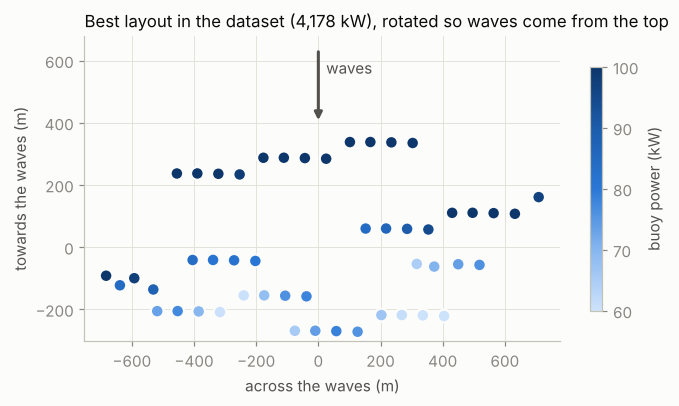

LIVE (all layouts)  front third 92.7 kW per buoy, back third 64.3 kW (-31%)


In [3]:
wave_frame()

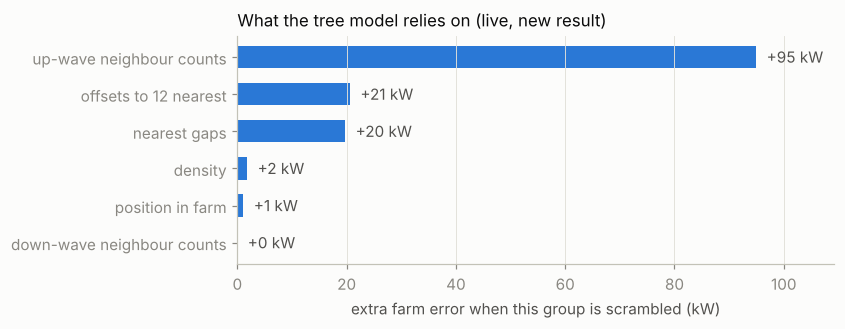

In [4]:
importance()

## 3. How the models use it
| | inputs | model | output |
|---|---|---|---|
| **Per-buoy model** | 49 positions → 40 features per buoy (neighbours in front, behind, gaps) | 300 boosted trees | each buoy's power → summed to farm power |
| **Model 1** | depth, distance to coast, slope, fetch | logistic regression / random forest | "don't trust ERA5 here" flag |
| **Site energy** | ERA5 wave height & period | simulator's power curve (no ML) | GWh per year |

## 4. Run it live
**Fair testing.** Near-identical layouts on both sides of a random split inflate the score.

In [5]:
leakage()

how we split train / test,farm R² (live)
random split,0.983
whole twin families held out,0.963


Full data: 0.982 → 0.961. The slides' 0.97 → 0.82 is the published pipeline, October run, different twin definition, **not re-tested**.

**Trees vs a simpler model.**

In [6]:
trees_vs_quadratic()

model (families held out),farm R² (live),error on the best 5% of layouts (live)
quadratic regression,0.935,79 kW
boosted trees (ours),0.963,77 kW


Trees win overall, but every model is far off on the best layouts → the simulator has to check them.

**Model 1: always against its baseline.**

In [7]:
model1()

"flag ""ERA5 wave height off by ≥ 8%"" (94 US buoys)",AUC (live)
distance to coast alone (no model),0.79
"logistic regression, tested on an unseen US region",0.71


LIVE  as a screen on 41,396 Indian Ocean coastal cells: 13.4% flagged; 6 of 6 recommended sites pass


## 5. Predict one unseen layout

In [8]:
predict_one()

LIVE  a layout from a family the model never saw: model 4,122.3 kW vs dataset 4,104.0 kW (+0.45%)


## 6. Wave Farm Lab: open [Wave_Farm_Lab.html](Wave_Farm_Lab.html)
Best in dataset → Unseen A → drag a back-row buoy → **Let the model optimise** (model's *claim* ≈ 4,253 kW vs the dataset's best 4,178 kW).

## 7. Before us vs ours
| before us | ours |
|---|---|
| Dataset and layout optimisers (Neshat et al. 2019, 2020) | Near-twin leakage test and fair scores |
| R² 0.97 layout model (Ganapathi Subramanian 2026) | Per-buoy model + simulator loop, with model-free controls |
| Cross-site transfer (Neshat et al. 2024) | Resonance-based site ranking, southern India & Sri Lanka |
| | Model 1 tested against a distance-to-coast baseline |

<details><summary><b>References</b> (click)</summary>

- Neshat, M., Abbasnejad, E., Shi, Q., et al. (2019). Adaptive neuro-surrogate-based optimisation method for wave energy converters placement optimisation. arXiv:1907.03076.
- Neshat, M., Alexander, B., Sergiienko, N. Y., & Wagner, M. (2020). Optimisation of large wave farms using a multi-strategy evolutionary framework. GECCO 2020. doi:10.1145/3377930.3390235.
- Neshat, M., Alexander, B., Sergiienko, N., & Wagner, M. (2020). Large-scale Wave Energy Farm [Dataset]. UCI Machine Learning Repository. doi:10.24432/C5GG7Q.
- Neshat, M., Sergiienko, N. Y., Rafiee, A., Mirjalili, S., Gandomi, A. H., & Boland, J. (2024). MetaWave Learner. Energy 304, 132122. doi:10.1016/j.energy.2024.132122.
- Amini, E. et al. (2020). Performance investigation on the different wave energy converters layouts in real wave scenarios. arXiv:2007.14012.
- Ganapathi Subramanian, P. (2026). Surrogate modelling of large-scale wave energy converter arrays using geometric feature engineering. J. Ocean Eng. Mar. Energy. doi:10.1007/s40722-026-00522-0.
- Babarit, A. (2015). A database of capture width ratio of wave energy converters. Renewable Energy 80, 610–628.
- Zheng, C. et al. (2021). Global oceanic wave energy resource dataset, with the Maritime Silk Road as a case study. Renewable Energy 169, 843–854.
- Hersbach, H. et al. (2020). The ERA5 global reanalysis. Q. J. R. Meteorol. Soc. 146, 1999–2049.
- GEBCO Compilation Group (2026). The GEBCO_2026 Grid.
- Sergiienko, N. (2019). WEC array simulator. MATLAB Central File Exchange #71840.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. JMLR 12, 2825–2830.
</details>

In [9]:
print(f'Total run time: {time.time()-T0:.0f} s')

Total run time: 47 s
